# Validating aggregation and stress: dependence checks, back-cast, severity and bottom-up against top-down

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 02 to 06 of this topic (the aggregation, the scenarios and the capital plan)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- list the tests that validate an economic capital model and a macro stress test (dossier 05, G.5 and H.7), say what each asks and what rule gives its light, and recompute each one with the engine from the committed documents;
- recompute the eight aggregation tests of the case and the Monte Carlo agreement test, and see the engine's horizon-and-level check turn red on a planted mismatch;
- recompute the satellite back-cast through 2020, read why all five satellites fail it, and see the engine refuse a back-cast whose fit window leaks into the episode;
- read the sign test of the macro sensitivities, the severity of each scenario against the global financial crisis and the static balance-sheet rules, and apply the bottom-up against top-down rule;
- say what the red and amber lights of the case mean for how far its numbers can be trusted.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The engine's test identifiers are printed as the engine writes them. Its messages and notes are written in English: this tree prints them as written, and the Spanish tree prints a translation from a table in the notebook that fails if the engine changes the text.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Import the engine and the helpers, and print the versions of the packages this notebook uses
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from scipy import stats
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.validation import aggregation as agg_tests
from riskvalidation.validation import portfolio as port_tests
from riskvalidation.validation import stress as stress_tests
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the **test rows** of **C18** (Banco Andino) and the inputs they need.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 0.8.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (the aggregation and the stress test rows, the marginals, the band, the back-cast block, the severity rows), `t-copula-baseline.json` (the correlation-stress band and the two aggregation tests the baseline does not carry), `fed-2026-severely-adverse.json`, `eba-2025-adverse.json` and `ngfs-delayed-transition.json` (the severity of each scenario) and `models-banco-andino.json` (the satellite coefficients). A **test row** is one engine test call stored as a dictionary: `test_id`, `model_id`, `segment`, `statistic`, `metric`, `light` and `extras`.
- **What the lights are.** The aggregation and stress tests are **Contraste internal gates**, stated as such, not regulatory thresholds and not hypothesis tests: each function states its rule in its docstring and records its parameters in `extras["thresholds"]`. The engine states no compliance claim.

In [2]:
# The notebook sits three folders below the repository root; a missing file stops the notebook and names its path
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("derived folder found:", DERIVED.is_dir())

baseline_doc = read_json("C18/baseline.json")
baseline = baseline_doc["outputs"]
agg = baseline["aggregation"]
second = read_json("C18/t-copula-baseline.json")
models = read_json("C18/models-banco-andino.json")["fit"]
variants = {name: read_json(f"C18/{name}.json") for name in ("eba-2025-adverse", "fed-2026-severely-adverse", "ngfs-delayed-transition")}
R = np.array(agg["correlation"]["matrix"])
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
band = {(r["method"], r["nu"]): r["capital_clp_m"] for r in agg["band"]}


def committed_row(document, test_id, segment=None):
    return next(t for t in document["tests"] if t["test_id"] == test_id and t.get("segment") == segment)


print("test rows in the baseline document:", len(baseline_doc["tests"]), "| in the t-copula document:", len(second["tests"]), "| baked by riskvalidation", baseline_doc["provenance"]["riskvalidation_version"])

derived folder found: True
test rows in the baseline document: 17 | in the t-copula document: 9 | baked by riskvalidation 0.9.0


## Method

### Step 1: the aggregation tests

Dossier 05 (G.5) lists what to check in an economic capital model: benchmark the aggregation against the simple sum and the square-root formula, report the copula-choice sensitivity, report the worst-case bounds, stress the inter-risk correlation, check that the allocation adds up and the sign of every diversification benefit, and check that one horizon and one confidence level apply. The engine has a test for each, and the rules are these (every gate is Contraste's own):

| Test | Rule for the light |
|---|---|
| `simple_sum_and_variance_covariance` | red if the aggregate is above the simple sum; amber if it is more than 10 percent from the square-root anchor; green otherwise |
| `copula_choice_sensitivity` | green up to 5 percent between the Gaussian and the largest t difference, amber up to 15 percent, red above |
| `worst_case_bracket` | red if any band row is outside the lower bound and the worst case |
| `correlation_stress` | red if capital falls when a correlation rises; amber if it rises more than 10 percent |
| `diversification_sign` | red if any diversified row is above the simple sum |
| `horizon_confidence_consistency` | red if any marginal is at another horizon or level than one year and 99.9 percent |
| `euler_additivity` | green if the contributions add up to the total within $10^{-6}$ |

The next cell recomputes the seven tests from the committed numbers (the capitals, the band, the stressed band and the Euler allocation) and prints each light and statistic beside the committed row.

In [3]:
# Recompute the seven aggregation tests from the committed numbers and print each beside the committed row
gaussian, lower, worst = band[("gaussian-copula", None)], band[("lower-bound", None)], band[("worst-case", None)]
t_caps = [(nu, band[("t-copula", nu)]) for nu in agg["nu_set"]["values"]]
between = [v for (method, nu), v in band.items() if method not in ("lower-bound", "worst-case")]
stressed = {(r["method"], r["nu"]): r["capital_clp_m"] for r in second["outputs"]["correlation_stress"]["aggregation"]["band"]}
diversified = [r["diversification_factor"] for r in agg["band"] if r["method"] in ("variance-covariance", "gaussian-copula", "t-copula")]
contributions = np.array([row["contribution_clp_m"] for row in agg["euler"]["allocation"]])
mine = {
    "aggregation.simple_sum_and_variance_covariance": agg_tests.simple_sum_and_variance_covariance(ec, R, gaussian),
    "aggregation.copula_choice_sensitivity": agg_tests.copula_choice_sensitivity(gaussian, t_caps),
    "aggregation.worst_case_bracket": agg_tests.worst_case_bracket(lower, between, worst),
    "aggregation.correlation_stress": agg_tests.correlation_stress(gaussian, stressed[("gaussian-copula", None)]),
    "aggregation.diversification_sign": agg_tests.diversification_sign(diversified),
    "aggregation.horizon_confidence_consistency": agg_tests.horizon_confidence_consistency([1] * 4, [0.999] * 4),
    "portfolio.euler_additivity": port_tests.euler_additivity(contributions, agg["euler"]["es_total_clp_m"], 1e-6),
}
print(f'{"test":48s} {"light":6s} {"statistic":>12s} | {"committed":6s} {"statistic":>12s} same')
for test_id, result in mine.items():
    row = committed_row(baseline_doc, test_id)
    same = result.light.value == row["light"] and bool(np.isclose(result.statistic, row["statistic"]))
    print(f'{test_id:48s} {result.light.value:6s} {result.statistic:12.4f} | {row["light"]:6s} {row["statistic"]:12.4f} {same}')

test                                             light     statistic | committed    statistic same
aggregation.simple_sum_and_variance_covariance   green        0.9316 | green        0.9316 True
aggregation.copula_choice_sensitivity            amber        0.1228 | amber        0.1228 True
aggregation.worst_case_bracket                   green   704814.1715 | green   704814.1715 True
aggregation.correlation_stress                   amber        0.1211 | amber        0.1211 True
aggregation.diversification_sign                 green        0.8394 | green        0.8394 True
aggregation.horizon_confidence_consistency       green        0.0000 | green        0.0000 True
portfolio.euler_additivity                       green   709389.9885 | green   709389.9885 True


Two of the seven are **amber**, and they say something. The copula choice moves the capital by up to 12.3 percent (the t with $\nu = 4$ against the Gaussian), above the 5 percent gate: the answer depends on a modelling choice that no data in the case can settle. And the market-credit stress to 0.8 raises the Gaussian row by 12.1 percent, above its 10 percent gate: the answer depends on a correlation that is a convention. Neither is a failure of the model; each is a **sensitivity the reader must see**, which is why the band is shown whole.

**The Monte Carlo agreement test.** In the one case where the square-root formula is exact, normal marginals with a Gaussian copula, a simulation must agree with it. `elliptical_mc_agreement(mc_capital, mc_se, vc_capital, z)` checks that the simulated capital is within $z = 3$ standard errors of the formula: it is the test of the simulator itself. The next cell runs that simulation as the pipeline does, with normal marginals that have the committed capitals ($\sigma_k = EC_k / z_{0.999}$), one million draws and seed 49 (the seed of the case, 42, plus 7), and compares with the committed row. It also runs the horizon-and-level check on a planted mismatch, one marginal at a ten-day horizon.

In [4]:
# The Monte Carlo agreement test with normal marginals and a Gaussian copula, and the horizon check on a planted mismatch
LEVEL = 0.999
z_level = stats.norm.ppf(LEVEL)
normal_ppfs = [(lambda u, s=capital / z_level: s * stats.norm.ppf(u)) for capital in ec]
simulation = cop.copula_aggregate(normal_ppfs, R, "gaussian", None, 0.0, LEVEL, 1_000_000, 49, 100_000)
vc_total = simple.variance_covariance(ec, R)
agreement = agg_tests.elliptical_mc_agreement(simulation.ec, simulation.var_se, vc_total)
row = committed_row(second, "aggregation.elliptical_mc_agreement")
print("simulated capital:", round(simulation.ec, 1), "| standard error:", round(simulation.var_se, 1), "| square-root anchor:", round(vc_total, 1))
print("statistic (in standard errors):", round(agreement.statistic, 4), "| light:", agreement.light.value, "| committed:", round(row["statistic"], 4), row["light"])
planted = agg_tests.horizon_confidence_consistency([1.0, 1.0, 10 / 250, 1.0], [0.999] * 4)
print("planted ten-day marginal: light:", planted.light.value, "| offending marginals:", planted.extras["offending_indices"], "| their names:", [agg["marginals"][i]["risk"] for i in planted.extras["offending_indices"]])

simulated capital: 526698.9 | standard error: 1587.1 | square-root anchor: 528106.4
statistic (in standard errors): -0.8868 | light: green | committed: -0.8868 green
planted ten-day marginal: light: red | offending marginals: [2] | their names: ['irrbb']


### Step 2: the satellite back-cast

A satellite is validated **out of time**: fit it on data that ends before an episode, run it through the episode on the **realised** macro variables, and compare predicted and realised loss rates (dossier 05, H.7). The case fits on 1985 to 2019 and back-casts 2020 Q1 to 2025 Q4, which holds the pandemic shock. `satellite_backcast(predicted, realised, quarters, fit_end, peak_amber, peak_red, timing_quarters)` compares the peaks:

- **statistic** the RMSE of predicted against realised; **metric** the timing error in quarters (predicted peak quarter less realised peak quarter);
- light **green** when the predicted peak is within 35 percent of the realised peak in size and within 2 quarters in timing, **amber** within 60 percent, **red** otherwise;
- the light **`error`** when the fit window is not strictly before the episode: a back-cast on data it was fitted on is leakage, and the test refuses to run.

The next cell recomputes the test for the five loan types from the committed predicted and realised quarters, prints the size ratio and the timing, and compares with the committed rows. It then plants a leak, a fit that ends in 2020 Q2.

In [5]:
# Recompute the back-cast test of each loan type from the committed quarters, and plant a fit window that leaks into the episode
backcast = {b["fed_loan_type"]: b for b in baseline["backcast"]["per_loan_type"]}
print(f'{"loan type":24s} {"peak ratio":>10s} {"timing":>7s} {"RMSE":>8s} {"light":6s} committed')
for loan_type, block in backcast.items():
    quarters = [q["quarter_end"] for q in block["quarters"]]
    result = stress_tests.satellite_backcast([q["predicted"] for q in block["quarters"]], [q["realised"] for q in block["quarters"]], quarters, block["fit_window"]["end"])
    row = committed_row(baseline_doc, "stress.satellite_backcast", loan_type)
    print(f'{loan_type:24s} {result.extras["peak_ratio"]:10.2f} {result.metric:7.0f} {result.statistic:8.4f} {result.light.value:6s} {row["light"]} (ratio {row["extras"]["peak_ratio"]:.2f}, timing {row["metric"]:.0f})')
block = backcast["credit-cards"]
leak = stress_tests.satellite_backcast([q["predicted"] for q in block["quarters"]], [q["realised"] for q in block["quarters"]], [q["quarter_end"] for q in block["quarters"]], "2020-06-30")
print("fit window ending 2020-06-30:", leak.light.value, "|", leak.notes)

loan type                peak ratio  timing     RMSE light  committed
commercial-industrial          4.55       0   0.0055 red    red (ratio 4.55, timing 0)
commercial-real-estate        13.14     -14   0.0079 red    red (ratio 13.14, timing -14)
residential                  252.13     -12   0.0068 red    red (ratio 252.13, timing -12)
credit-cards                   4.30     -17   0.0371 red    red (ratio 4.30, timing -17)
other-consumer                 2.09     -21   0.0051 red    red (ratio 2.09, timing -21)
fit window ending 2020-06-30: error | fit_end 2020-06-30 is not before the first quarter of the episode 2020-03-31: the fit window overlaps the episode it predicts (leakage)


All five satellites are **red**. Every one predicts its largest loss rate in 2020 Q2, the quarter of the shock, from 2.1 times the realised peak for other consumer loans to 252 times for residential mortgages; but only commercial and industrial loans actually peaked then, and the other four realised their peaks 12 to 21 quarters later. The satellites **react strongly to the realised macro variables of 2020**, and the realised 2020 charge-offs did not follow. A validator reads this as a finding about the stressed numbers of the case: the credit loss of a severe scenario rests on satellites that would have **overstated** the one downturn that fell inside the back-cast.

The figure draws predicted against realised rates for the five types.

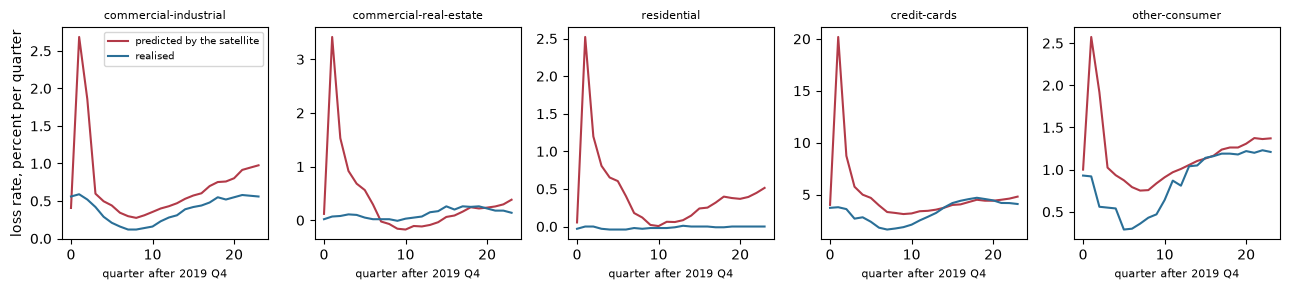

In [6]:
# Draw the predicted and realised loss rates of the back-cast for the five loan types
fig, axes = plt.subplots(1, 5, figsize=(13, 3), sharex=True)
for ax, (loan_type, block) in zip(axes, backcast.items()):
    ax.plot([q["predicted"] * 100 for q in block["quarters"]], label="predicted by the satellite", color="#b23a48")
    ax.plot([q["realised"] * 100 for q in block["quarters"]], label="realised", color="#2a6f97")
    ax.set_title(loan_type, fontsize=8)
    ax.set_xlabel("quarter after 2019 Q4", fontsize=8)
axes[0].set_ylabel("loss rate, percent per quarter")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

### Step 3: signs, severity, the static rules and bottom-up against top-down

**Signs.** `sensitivity_monotonicity(estimates, expected_signs)` counts the coefficients with the wrong sign against the sign declared **before** the fit (growth lowers the loss rate: negative; unemployment raises it: positive; the autoregressive term: positive), so the projected loss is monotone in the severity of the path. It is red when any coefficient is wrong.

**Severity.** `scenario_severity(path_peak, history_peak, is_stress, minimum)` compares the peak deviation of a scenario variable with the same deviation in the global financial crisis (2008 Q1 to 2009 Q4): the ratio must be at least 0.75, green if so and **amber** below (no red: a mild stress is a finding about the scenario, not a failure); the baseline is not a stress path and is `not_evaluated`.

**Static rules.** `static_balance_sheet_rules` was run in notebook 05.

**Bottom-up against top-down.** `bottom_up_vs_top_down(bottom_up, top_down, amber, red)` compares the bank's stressed loss with a **challenger** model's: green within 25 percent, amber within 50, red beyond. The case bakes no top-down challenger, so the rule is shown on the one pair of totals the documents give that differ only by scenario, the three-year loss of the Federal Reserve's and the EBA's adverse scenarios, as a demonstration of the rule and not as a challenger comparison.

The next cell recomputes the sign test from the coefficients and the signs declared in the models document, the severity of every scenario from the severity rows, and the bottom-up rule, and compares with the committed rows.

In [7]:
# Recompute the sign test, the severity of every scenario and the bottom-up rule, and compare with the committed rows
estimates, signs, labels = [], [], []
for model in models["satellites"]:
    for coefficient in model["coefficients"]:
        estimates.append(coefficient["estimate"])
        signs.append(coefficient["expected_sign"])
        labels.append(f'{model["fed_loan_type"]}:{coefficient["name"]}')
sign_test = stress_tests.sensitivity_monotonicity(estimates, signs)
row = committed_row(baseline_doc, "stress.sensitivity_monotonicity", None)
print("coefficients tested:", sign_test.n, "| wrong sign:", int(sign_test.statistic), "| light:", sign_test.light.value, "| committed:", row["light"], int(row["statistic"]))
for index in sign_test.extras["offending_indices"]:
    print(f"  {labels[index]:46s} estimate {estimates[index]:+.5f}, expected {signs[index]}")
print(f'{"scenario":28s} {"variable":18s} {"peak":>6s} {"crisis":>7s} {"ratio":>6s} light      committed')
for name, document in {"baseline": baseline_doc, **variants}.items():
    for severity in document["outputs"]["severity"]["rows"]:
        result = stress_tests.scenario_severity(severity["path_peak_deviation"], severity["history_peak_deviation"], severity["is_stress"])
        row = committed_row(document, "stress.scenario_severity", severity["maps_to_regressor"])
        print(f'{name:28s} {severity["maps_to_regressor"]:18s} {severity["path_peak_deviation"]:6.2f} {severity["history_peak_deviation"]:7.2f} {"-" if result.statistic != result.statistic else format(result.statistic, ".3f"):>6s} {result.light.value:10s} {row["light"]}')
totals = {name: sum(r["total"] for r in document["outputs"]["losses"]["scenario_losses"]) for name, document in variants.items()}
demo = stress_tests.bottom_up_vs_top_down(totals["eba-2025-adverse"], totals["fed-2026-severely-adverse"])
print("rule demonstration, EBA adverse loss over Federal Reserve severe loss less 1:", round(demo.statistic, 4), "| light:", demo.light.value, "| gates:", demo.extras["thresholds"])

coefficients tested: 30 | wrong sign: 6 | light: red | committed: red 6
  commercial-industrial:real_gdp_growth_lag0     estimate +0.00069, expected negative
  commercial-real-estate:real_gdp_growth_lag1    estimate +0.00005, expected negative
  residential:real_gdp_growth_lag0               estimate +0.00005, expected negative
  residential:real_gdp_growth_lag1               estimate +0.00006, expected negative
  credit-cards:real_gdp_growth_lag0              estimate +0.00038, expected negative
  credit-cards:real_gdp_growth_lag1              estimate +0.00057, expected negative
scenario                     variable             peak  crisis  ratio light      committed
baseline                     unemployment_rate    0.20    5.10      - not_evaluated not_evaluated
baseline                     real_gdp_growth      1.10   11.00      - not_evaluated not_evaluated
baseline                     prime_rate           1.00    4.20      - not_evaluated not_evaluated
eba-2025-adverse           

## Results

The next cell tallies every test of the case by light, counting the committed rows of the baseline and the aggregation documents, so that the reader sees the whole battery at once.

In [8]:
# Tally the committed test rows of C18 by test and light across the baseline and the t-copula documents
from collections import Counter

rows = baseline_doc["tests"] + [t for t in second["tests"] if t["test_id"] in ("aggregation.elliptical_mc_agreement", "aggregation.rosenberg_schuermann_reference")]
by_light = Counter(t["light"] for t in rows)
print("committed rows:", len(rows), "| by light:", dict(by_light))
for test_id in sorted({t["test_id"] for t in rows}):
    print(f'{test_id:48s}', dict(Counter(t["light"] for t in rows if t["test_id"] == test_id)))

committed rows: 19 | by light: {'green': 8, 'amber': 2, 'red': 6, 'not_evaluated': 3}
aggregation.copula_choice_sensitivity            {'amber': 1}
aggregation.correlation_stress                   {'amber': 1}
aggregation.diversification_sign                 {'green': 1}
aggregation.elliptical_mc_agreement              {'green': 1}
aggregation.horizon_confidence_consistency       {'green': 1}
aggregation.rosenberg_schuermann_reference       {'green': 1}
aggregation.simple_sum_and_variance_covariance   {'green': 1}
aggregation.worst_case_bracket                   {'green': 1}
portfolio.euler_additivity                       {'green': 1}
stress.satellite_backcast                        {'red': 5}
stress.scenario_severity                         {'not_evaluated': 3}
stress.sensitivity_monotonicity                  {'red': 1}
stress.static_balance_sheet_rules                {'green': 1}


- **Every aggregation test recomputed from the committed numbers gives the committed light and statistic**: simple sum and square-root rule green (the aggregate is 93.2 percent of the anchor), worst-case bracket green, diversification sign green, horizon and level green, Euler additivity green, and the two amber lights, copula choice (12.3 percent against a 5 percent gate) and correlation stress (12.1 percent against 10 percent).
- **The Monte Carlo agreement test is green on a fresh simulation** that reproduces the committed row: the capital with normal marginals and a Gaussian copula is 526,699 with a standard error of 1,587, 0.89 standard errors below the square-root anchor of 528,106 (gate: 3). A planted ten-day marginal turns the horizon check red and names interest rate risk.
- **All five satellites are red in the back-cast.** The predicted peak is 2.1 to 252 times the realised one (4.55 for commercial and industrial, 13.14 for commercial real estate, 252.13 for residential, 4.30 for cards and 2.09 for other consumer); only commercial and industrial loans peaked in the predicted quarter, and the others peaked 12 to 21 quarters later. A fit window ending in 2020 Q2 is refused with the light `error`.
- **Six of the 30 coefficients have the wrong sign**: the GDP-growth coefficients of commercial and industrial (lag 0), commercial real estate (lag 1), residential (lags 0 and 1) and credit cards (lags 0 and 1) are slightly positive where a negative sign was declared before the fit. The sign test is red.
- **Severity is mixed.** The Federal Reserve severely adverse scenario passes on unemployment (1.078) and the prime rate (0.929) and is amber on GDP growth (0.582 of the crisis); the EBA adverse is amber on GDP growth (0.711) and green elsewhere; every NGFS variable is amber (0.04 to 0.14), because the delayed-transition shock is a climate-policy shock far milder in macro terms than the crisis; the baseline is `not_evaluated`.
- **The bottom-up rule is shown, not run on a challenger**: the EBA adverse three-year loss is 7.3 percent above the Federal Reserve severe one, green against the 25 and 50 percent gates.
- **Across the 19 committed test rows: 8 green, 2 amber, 6 red and 3 not evaluated.** The reds are all in the stress layer, and the headline of the case says that its stressed credit loss rests on satellites that fail their own back-cast.

What this notebook does not show: the gates are Contraste's internal ones, so a light is a reading of that policy and not a regulatory verdict; the case has no challenger model, so bottom-up against top-down was demonstrated and not performed; and the lights say the satellites are weak, not what a better model would give.

## Summary

- The engine has one test for each check of dossier 05: seven for the aggregation (plus the Monte Carlo agreement and the published reference) and six for the stress, each with a stated rule and gates that are Contraste's, not the regulator's.
- Recomputed from the committed numbers, every aggregation test and the back-cast, sign and severity tests give the committed light and statistic; the Monte Carlo agreement test is green on a fresh simulation.
- The two amber aggregation lights are sensitivities (the copula choice and the correlation stress) that the band exists to show; the red lights are about the **satellites**: all five fail their back-cast and six coefficients have the wrong sign.
- The tests refuse what they should: a mismatched horizon is red, a fit window that leaks into the episode is `error`, and a scenario milder than the global financial crisis is amber.
- The consequence is not that the case is wrong, but that its stressed credit loss rests on satellites that its own validation battery marks red.

**What to try next.** Replace the amber and red gates of one test with your own and see which lights change; then continue with notebook 08, the state of the art, which sets the case's aggregation and satellites next to the supervisory models and the model-risk measures.

## References

- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Dossier 05 of the persisted Contraste research (G.5, validation tests for an economic capital model, and H.7, what validators test in a stress model), as summarised in the SDD's research basis.
- This repository: `docs/contracts/engine/aggregation-api.md` and `docs/contracts/engine/stress-api.md` (the validation tests and their rules) and `docs/design/features/c18/validation.md`.